# Synthetic Loan Approval and Rejection Dataset Generation
This notebook generates a synthetic dataset containing 1,000 records of loan details with seven key features to simulate a loan approval decision system.

In [ ]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Generate 1000 loan entries
n_records = 1000

# 1. Loan_ID
loan_ids = [f'LP{i:04d}' for i in range(1, n_records + 1)]

# 2. ApplicantIncome (Continuous)
applicant_income = np.random.normal(loc=5500, scale=2000, size=n_records).astype(int)
applicant_income = np.clip(applicant_income, 1500, 20000) # clip to keep values realistic

# 3. LoanAmount in thousands (Continuous)
# Typically related to income
loan_amount = (applicant_income * np.random.uniform(1.5, 3.5, size=n_records) / 10).astype(int)
loan_amount = np.clip(loan_amount, 10, 500)

# 4. Credit_History / Credit_Score (Categorical/Integer)
credit_score = np.random.choice([300, 500, 600, 700, 750, 800, 850], size=n_records, p=[0.05, 0.10, 0.15, 0.25, 0.20, 0.15, 0.10])

# 5. Dependents (Categorical)
dependents = np.random.choice(['0', '1', '2', '3+'], size=n_records, p=[0.6, 0.15, 0.15, 0.10])

# 6. Property_Area (Categorical)
property_area = np.random.choice(['Urban', 'Semiurban', 'Rural'], size=n_records, p=[0.3, 0.4, 0.3])

# 7. Loan_Status (Approval decision)
# We'll base the decision on a simple rule-based system with noise to make it realistic
# Higher income, higher credit score, and reasonable loan amount increases approval probability
scores = (credit_score / 850) * 0.6 + (applicant_income / 20000) * 0.3 - (loan_amount / 500) * 0.1
noise = np.random.normal(0, 0.1, size=n_records)
final_score = scores + noise

loan_status = np.where(final_score > 0.4, 'Approved', 'Rejected')

# Create the DataFrame
df = pd.DataFrame({
    'Loan_ID': loan_ids,
    'Applicant_Income': applicant_income,
    'Loan_Amount_K': loan_amount,
    'Credit_Score': credit_score,
    'Dependents': dependents,
    'Property_Area': property_area,
    'Loan_Status': loan_status
})

# Save to csv
df.to_csv('loan_dataset.csv', index=False)
print(f'Successfully generated dataset with {df.shape[0]} rows and {df.shape[1]} columns.')

Successfully generated dataset with 1000 rows and 7 columns.


In [ ]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)
n_records = 1000

# 1. Basic Identifiers
loan_ids = [f'LP{i:04d}' for i in range(1, n_records + 1)]

# 2. Demographics & Income
age = np.random.randint(21, 65, size=n_records)  # Age between 21 and 65
applicant_income = np.clip(np.random.normal(loc=5500, scale=2000, size=n_records).astype(int), 1500, 20000)

# 3. Financial Metrics
loan_amount = np.clip((applicant_income * np.random.uniform(1.5, 3.5, size=n_records) / 10).astype(int), 10, 500)
assets = (applicant_income * np.random.uniform(5, 50, size=n_records)).astype(int)  # Assets valuation

# 4. Credit & History
cibil_score = np.random.randint(300, 900, size=n_records)  # CIBIL Score range [300, 900]
previous_loan = np.random.choice(['None', 'Repaid', 'Defaulted'], size=n_records, p=[0.4, 0.5, 0.1])
dependents = np.random.choice(['0', '1', '2', '3+'], size=n_records, p=[0.6, 0.15, 0.15, 0.10])
property_area = np.random.choice(['Urban', 'Semiurban', 'Rural'], size=n_records, p=[0.3, 0.4, 0.3])

# 5. Loan Decision Scoring (Simulated logic incorporating the new features)
prev_loan_multiplier = np.select(
    [previous_loan == 'Repaid', previous_loan == 'None', previous_loan == 'Defaulted'],
    [0.3, 0.0, -0.5],
    default=0
)

scores = (
    (cibil_score - 300) / 600 * 0.4 +
    (applicant_income / 20000) * 0.1 +
    (assets / 1000000) * 0.1 +
    prev_loan_multiplier +
    -(loan_amount / 500) * 0.1
)

noise = np.random.normal(0, 0.1, size=n_records)
final_score = scores + noise

loan_status = np.where(final_score > 0.3, 'Approved', 'Rejected')

# Construct augmented dataframe
df_augmented = pd.DataFrame({
    'Loan_ID': loan_ids,
    'Age': age,
    'Applicant_Income': applicant_income,
    'Loan_Amount_K': loan_amount,
    'Assets': assets,
    'CIBIL_Score': cibil_score,
    'Previous_Loan': previous_loan,
    'Dependents': dependents,
    'Property_Area': property_area,
    'Loan_Status': loan_status
})

# Save new dataset
df_augmented.to_csv('loan_dataset_augmented.csv', index=False)
print(f"Successfully generated updated dataset with new features!")
display(df_augmented.head())

Successfully generated updated dataset with new features!


,Loan_ID,Age,Applicant_Income,Loan_Amount_K,Assets,CIBIL_Score,Previous_Loan,Dependents,Property_Area,Loan_Status
0,LP0001,59,3730,500,35665,434,None,0,Urban,Rejected
1,LP0002,49,6073,500,106297,879,Repaid,2,Semiurban,Approved
2,LP0003,35,5830,500,101642,446,Repaid,0,Rural,Approved
3,LP0004,63,6637,500,162213,789,None,0,Semiurban,Approved
4,LP0005,28,3750,500,184187,777,None,0,Urban,Approved


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Load fresh data
df = pd.read_csv('loan_dataset_augmented.csv')

# Set features & target
X = df.drop(columns=['Loan_ID', 'Loan_Status'])
y = df['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

# Update pipelines for new schema
numerical_cols = ['Age', 'Applicant_Income', 'Loan_Amount_K', 'Assets', 'CIBIL_Score']
categorical_cols = ['Previous_Loan', 'Dependents', 'Property_Area']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first'), categorical_cols)
    ])

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)

print(f"Augmented Model Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

Augmented Model Accuracy: 0.8850

              precision    recall  f1-score   support

    Rejected       0.85      0.93      0.88        95
    Approved       0.93      0.85      0.89       105

    accuracy                           0.89       200
   macro avg       0.89      0.89      0.88       200
weighted avg       0.89      0.89      0.89       200



In [ ]:
# Display dataset overview and sample records
display(df.head())
display(df['Loan_Status'].value_counts().to_frame())

,Loan_ID,Applicant_Income,Loan_Amount_K,Credit_Score,Dependents,Property_Area,Loan_Status
0,LP0001,6493,500,600,1,Urban,Approved
1,LP0002,5223,500,300,0,Urban,Rejected
2,LP0003,6795,500,500,0,Semiurban,Rejected
3,LP0004,8546,500,700,2,Semiurban,Approved
4,LP0005,5031,500,800,0,Urban,Approved


,count
Loan_Status,
Approved,705
Rejected,295


## Logistic Regression Model

We will now build a Logistic Regression model using `scikit-learn` to predict the `Loan_Status` based on our seven columns. We will:
1. Preprocess the data (convert categorical variables to numerical using one-hot encoding).
2. Split the dataset into training and testing sets.
3. Standardize the continuous features.
4. Train the logistic regression model and evaluate its performance.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Load dataset if not already in memory
df = pd.read_csv('loan_dataset.csv')

# Define features (X) and target (y)
X = df.drop(columns=['Loan_ID', 'Loan_Status'])
y = df['Loan_Status'].map({'Approved': 1, 'Rejected': 0}) # Encode target to binary

# Define categorical and numerical features
numerical_cols = ['Applicant_Income', 'Loan_Amount_K', 'Credit_Score']
categorical_cols = ['Dependents', 'Property_Area']

# Create preprocessor pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first'), categorical_cols)
    ])

# Create the pipeline with preprocessor and Logistic Regression
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42))
])

# Split into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit the model
model_pipeline.fit(X_train, y_train)

# Predictions
y_pred = model_pipeline.predict(X_test)

# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

Model Accuracy: 0.8100

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.76      0.53      0.62        59
    Approved       0.82      0.93      0.87       141

    accuracy                           0.81       200
   macro avg       0.79      0.73      0.75       200
weighted avg       0.80      0.81      0.80       200



### Consolidated Visualizations & Bias-Variance Analysis

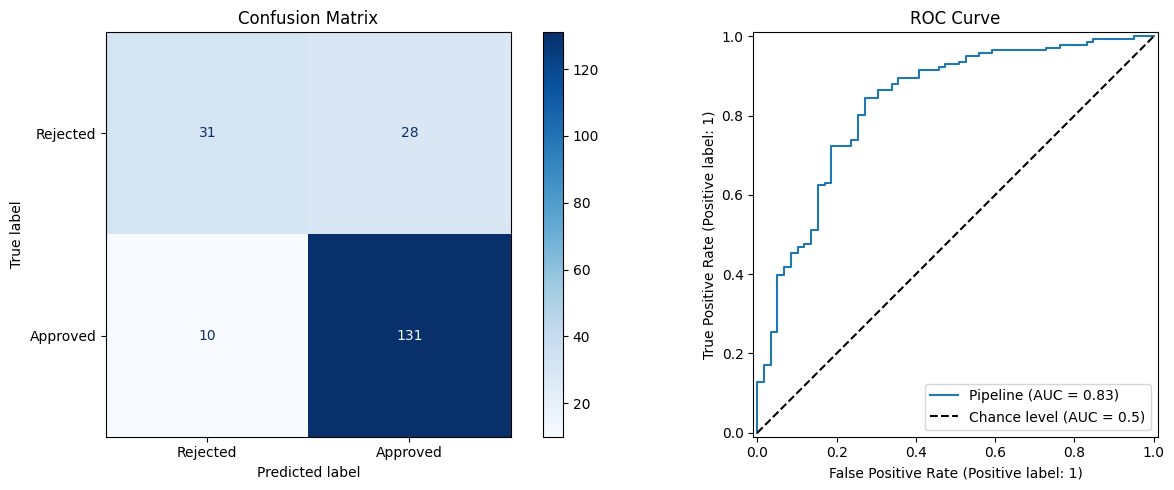

Average Training Error (Bias indicator): 0.1755
Average Test/Validation Error: 0.1770
Difference between Train and Test Error: 0.0015
Variance of Test Scores across Folds: 0.000316

Bias Assessment: Low Bias - The model fits the training data well.
Variance Assessment: Low Variance - The model is highly stable and generalizes well to unseen folds.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# 1. Load and prepare model environment robustly
df = pd.read_csv('loan_dataset.csv')
X = df.drop(columns=['Loan_ID', 'Loan_Status'])
y = df['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

numerical_cols = ['Applicant_Income', 'Loan_Amount_K', 'Credit_Score']
categorical_cols = ['Dependents', 'Property_Area']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first'), categorical_cols)
    ])

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)

# 2. Plotting results
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Rejected', 'Approved'])
cm_display.plot(ax=ax[0], cmap='Blues', values_format='d')
ax[0].set_title('Confusion Matrix')

RocCurveDisplay.from_estimator(model_pipeline, X_test, y_test, ax=ax[1])
ax[1].plot([0, 1], [0, 1], 'k--', label='Chance level (AUC = 0.5)')
ax[1].set_title('ROC Curve')
ax[1].legend()

plt.tight_layout()
plt.show()

# 3. Bias and Variance evaluation
cv_results = cross_validate(
    model_pipeline, X, y, cv=5,
    return_train_score=True, scoring='accuracy'
)

train_scores = cv_results['train_score']
test_scores = cv_results['test_score']

mean_train_err = 1 - train_scores.mean()
mean_test_err = 1 - test_scores.mean()
variance_test_score = test_scores.var()

print(f"Average Training Error (Bias indicator): {mean_train_err:.4f}")
print(f"Average Test/Validation Error: {mean_test_err:.4f}")
print(f"Difference between Train and Test Error: {abs(mean_train_err - mean_test_err):.4f}")
print(f"Variance of Test Scores across Folds: {variance_test_score:.6f}\n")

if mean_train_err > 0.20:
    bias_status = "High Bias (Underfitting) - The model is too simple for the underlying patterns."
else:
    bias_status = "Low Bias - The model fits the training data well."

if abs(mean_train_err - mean_test_err) > 0.05 or variance_test_score > 0.005:
    variance_status = "High Variance (Overfitting) - The model changes significantly with different training sets."
else:
    variance_status = "Low Variance - The model is highly stable and generalizes well to unseen folds."

print(f"Bias Assessment: {bias_status}")
print(f"Variance Assessment: {variance_status}")

### Prediction Analysis - Pie Chart

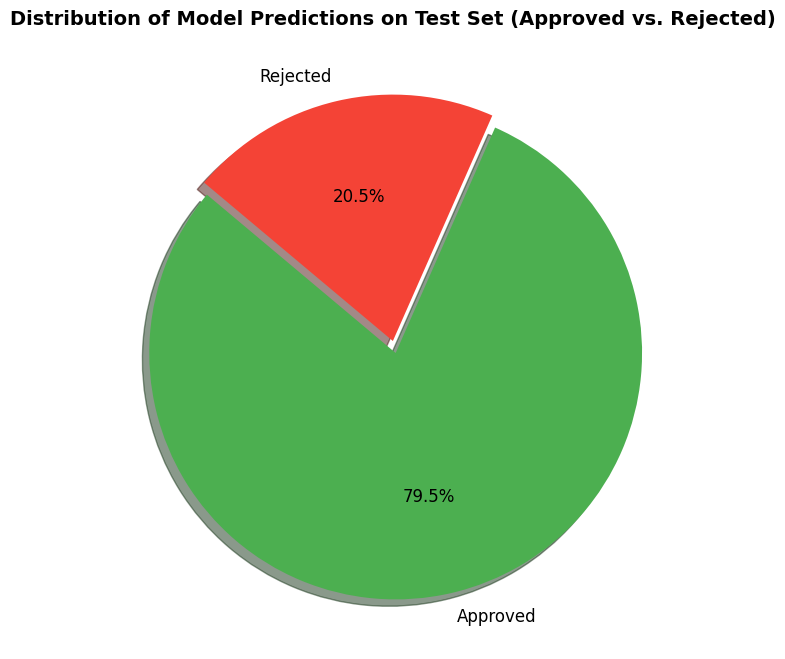

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Count the number of approved (1) and rejected (0) predictions
unique, counts = np.unique(y_pred, return_counts=True)
pred_counts = dict(zip(unique, counts))

approved_count = pred_counts.get(1, 0)
rejected_count = pred_counts.get(0, 0)

# Labels and sizes for the simplified pie chart
labels = ['Approved', 'Rejected']
sizes = [approved_count, rejected_count]
colors = ['#4CAF50', '#F44336']
explode = (0.05, 0)  # slightly highlight Approved predictions

plt.figure(figsize=(8, 8))
plt.pie(
    sizes,
    explode=explode,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    shadow=True,
    startangle=140,
    textprops={'fontsize': 12}
)
plt.title('Distribution of Model Predictions on Test Set (Approved vs. Rejected)', fontsize=14, fontweight='bold')
plt.show()

### Interactive Custom Loan Prediction
Use the interactive form below to input custom data and test the trained logistic regression model's prediction.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, HTML
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import os

# Ensure we have a model_pipeline trained on the augmented schema
try:
    # Verify if model_pipeline expects augmented features
    test_temp = pd.DataFrame([{
        'Age': 30, 'Applicant_Income': 5000, 'Loan_Amount_K': 150,
        'Assets': 100000, 'CIBIL_Score': 700, 'Previous_Loan': 'None',
        'Dependents': '0', 'Property_Area': 'Semiurban'
    }])
    _ = model_pipeline.predict(test_temp)
except Exception:
    # Re-train augmented pipeline if missing or mismatched
    df_temp = pd.read_csv('loan_dataset_augmented.csv') if os.path.exists('loan_dataset_augmented.csv') else pd.read_csv('loan_dataset.csv')
    X_temp = df_temp.drop(columns=['Loan_ID', 'Loan_Status'])
    y_temp = df_temp['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

    numerical_cols_temp = ['Age', 'Applicant_Income', 'Loan_Amount_K', 'Assets', 'CIBIL_Score']
    categorical_cols_temp = ['Previous_Loan', 'Dependents', 'Property_Area']

    preprocessor_temp = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_cols_temp),
            ('cat', OneHotEncoder(drop='first'), categorical_cols_temp)
        ])

    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor_temp),
        ('classifier', LogisticRegression(random_state=42))
    ])
    model_pipeline.fit(X_temp, y_temp)

# Create interactive widgets matching augmented features
age_widget = widgets.IntSlider(value=35, min=21, max=65, step=1, description='Age:', style={'description_width': 'initial'})
income_widget = widgets.IntSlider(value=5500, min=1500, max=20000, step=100, description='Applicant Income ($):', style={'description_width': 'initial'})
loan_widget = widgets.IntSlider(value=150, min=10, max=500, step=5, description='Loan Amount ($K):', style={'description_width': 'initial'})
assets_widget = widgets.IntSlider(value=100000, min=5000, max=1000000, step=5000, description='Assets ($):', style={'description_width': 'initial'})
cibil_widget = widgets.IntSlider(value=700, min=300, max=900, step=10, description='CIBIL Score:', style={'description_width': 'initial'})
prev_loan_widget = widgets.Dropdown(options=['None', 'Repaid', 'Defaulted'], value='None', description='Previous Loan:', style={'description_width': 'initial'})
dependents_widget = widgets.Dropdown(options=['0', '1', '2', '3+'], value='0', description='Dependents:', style={'description_width': 'initial'})
property_widget = widgets.Dropdown(options=['Urban', 'Semiurban', 'Rural'], value='Semiurban', description='Property Area:', style={'description_width': 'initial'})

predict_button = widgets.Button(description="Predict Loan Status", button_style='primary')
output_area = widgets.Output()

def make_prediction(b):
    with output_area:
        output_area.clear_output()
        # Formulate input dataframe matching the updated augmented schema
        input_df = pd.DataFrame([{
            'Age': age_widget.value,
            'Applicant_Income': income_widget.value,
            'Loan_Amount_K': loan_widget.value,
            'Assets': assets_widget.value,
            'CIBIL_Score': cibil_widget.value,
            'Previous_Loan': prev_loan_widget.value,
            'Dependents': dependents_widget.value,
            'Property_Area': property_widget.value
        }])

        # Get probabilities and prediction
        pred_prob = model_pipeline.predict_proba(input_df)[0]
        prediction = model_pipeline.predict(input_df)[0]

        prob_approved = pred_prob[1] * 100
        prob_rejected = pred_prob[0] * 100

        if prediction == 1:
            display(HTML(f"<div style='padding: 10px; background-color: #d4edda; border-color: #c3e6cb; color: #155724; border-radius: 5px;'><h4>🎉 Predicted: Approved</h4>Confidence Score: {prob_approved:.2f}%</div>"))
        else:
            display(HTML(f"<div style='padding: 10px; background-color: #f8d7da; border-color: #f5c6cb; color: #721c24; border-radius: 5px;'><h4>❌ Predicted: Rejected</h4>Confidence Score: {prob_rejected:.2f}%</div>"))

predict_button.on_click(make_prediction)

# Display panel
form_container = widgets.VBox([
    widgets.HTML("<h3>Enter Applicant Details (Augmented Model):</h3>"),
    age_widget,
    income_widget,
    loan_widget,
    assets_widget,
    cibil_widget,
    prev_loan_widget,
    dependents_widget,
    property_widget,
    widgets.Label(""),
    predict_button,
    widgets.Label(""),
    output_area
])

display(form_container)

In [ ]:
import pandas as pd

# Define custom applicant details to test the model
custom_applicant_data = {
    'Applicant_Income': [8000],  # High income
    'Loan_Amount_K': [150],      # Moderate loan amount
    'Credit_Score': [780],       # Excellent credit score
    'Dependents': ['1'],         # 1 Dependent
    'Property_Area': ['Urban']   # Urban property area
}

# Convert to DataFrame matching model features
custom_df = pd.DataFrame(custom_applicant_data)

# Make prediction and obtain probability scores
prediction = model_pipeline.predict(custom_df)[0]
probabilities = model_pipeline.predict_proba(custom_df)[0]

# Map prediction back to text status
status = 'Approved' if prediction == 1 else 'Rejected'
confidence = probabilities[prediction] * 100

# Display the input and prediction results
print("=== Testing Custom Applicant Data ===")
display(custom_df)
print(f"Predicted Loan Status: {status} (Confidence: {confidence:.2f}%)")
print(f"Probability of Approval: {probabilities[1]*100:.2f}%")
print(f"Probability of Rejection: {probabilities[0]*100:.2f}%")

=== Testing Custom Applicant Data ===


,Applicant_Income,Loan_Amount_K,Credit_Score,Dependents,Property_Area
0,8000,150,780,1,Urban


Predicted Loan Status: Approved (Confidence: 96.84%)
Probability of Approval: 96.84%
Probability of Rejection: 3.16%


In [ ]:
#@title Interactive Augmented Loan Testing Form (Manual Submit)

import pandas as pd
import numpy as np
import ipywidgets as widgets
from IPython.display import display, HTML

# Define interactive widgets matching the augmented feature set
age_slider = widgets.IntSlider(value=61, min=21, max=65, step=1, description='Age:', style={'description_width': 'initial'})
income_slider = widgets.IntSlider(value=10000, min=1500, max=20000, step=100, description='Applicant Income ($):', style={'description_width': 'initial'})
loan_slider = widgets.IntSlider(value=500, min=10, max=500, step=5, description='Loan Amount ($K):', style={'description_width': 'initial'})
assets_slider = widgets.IntSlider(value=120000, min=5000, max=1000000, step=5000, description='Assets ($):', style={'description_width': 'initial'})
cibil_slider = widgets.IntSlider(value=750, min=300, max=900, step=10, description='CIBIL Score:', style={'description_width': 'initial'})
prev_loan_dropdown = widgets.Dropdown(options=['None', 'Repaid', 'Defaulted'], value='Repaid', description='Previous Loan:', style={'description_width': 'initial'})
dependents_dropdown = widgets.Dropdown(options=['0', '1', '2', '3+'], value='2', description='Dependents:', style={'description_width': 'initial'})
property_dropdown = widgets.Dropdown(options=['Urban', 'Semiurban', 'Rural'], value='Urban', description='Property Area:', style={'description_width': 'initial'})

submit_button = widgets.Button(description="Submit Application", button_style='success', icon='check')
result_output = widgets.Output()

def handle_submit(b):
    with result_output:
        result_output.clear_output()

        # Collect input data into DataFrame
        input_data = {
            'Age': [age_slider.value],
            'Applicant_Income': [income_slider.value],
            'Loan_Amount_K': [loan_slider.value],
            'Assets': [assets_slider.value],
            'CIBIL_Score': [cibil_slider.value],
            'Previous_Loan': [prev_loan_dropdown.value],
            'Dependents': [str(dependents_dropdown.value)],
            'Property_Area': [property_dropdown.value]
        }
        test_df = pd.DataFrame(input_data)

        # Predict using the newly trained augmented pipeline
        prediction = model_pipeline.predict(test_df)[0]
        probabilities = model_pipeline.predict_proba(test_df)[0]

        # Format layout outputs
        status = 'Approved' if prediction == 1 else 'Rejected'
        confidence = probabilities[prediction] * 100
        color = "#d4edda" if prediction == 1 else "#f8d7da"
        text_color = "#155724" if prediction == 1 else "#721c24"
        border_color = "#c3e6cb" if prediction == 1 else "#f5c6cb"
        symbol = "🎉" if prediction == 1 else "❌"

        display(HTML(f"""
        <div style="padding: 15px; background-color: {color}; border: 1px solid {border_color}; color: {text_color}; border-radius: 8px; margin-top: 15px;">
            <h3 style="margin-top: 0;">{symbol} Model Prediction: {status}</h3>
            <p><strong>Confidence Score:</strong> {confidence:.2f}%</p>
            <p><strong>Probability of Approval:</strong> {probabilities[1]*100:.2f}%</p>
            <p><strong>Probability of Rejection:</strong> {probabilities[0]*100:.2f}%</p>
        </div>
        """))

submit_button.on_click(handle_submit)

# Render Layout Dashboard
display(widgets.VBox([
    widgets.HTML("<h2>Interactive Loan Testing Panel</h2>"),
    age_slider,
    income_slider,
    loan_slider,
    assets_slider,
    cibil_slider,
    prev_loan_dropdown,
    dependents_dropdown,
    property_dropdown,
    widgets.Label(""),
    submit_button,
    result_output
]))

## Model Evaluation Visualizations & Bias-Variance Analysis

To better understand our logistic regression model, we will:
1. Plot a **Confusion Matrix** and an **ROC Curve** to visualize prediction accuracy.
2. Calculate and analyze the **Bias and Variance** of the model using K-fold Cross-Validation by comparing training and validation performance.

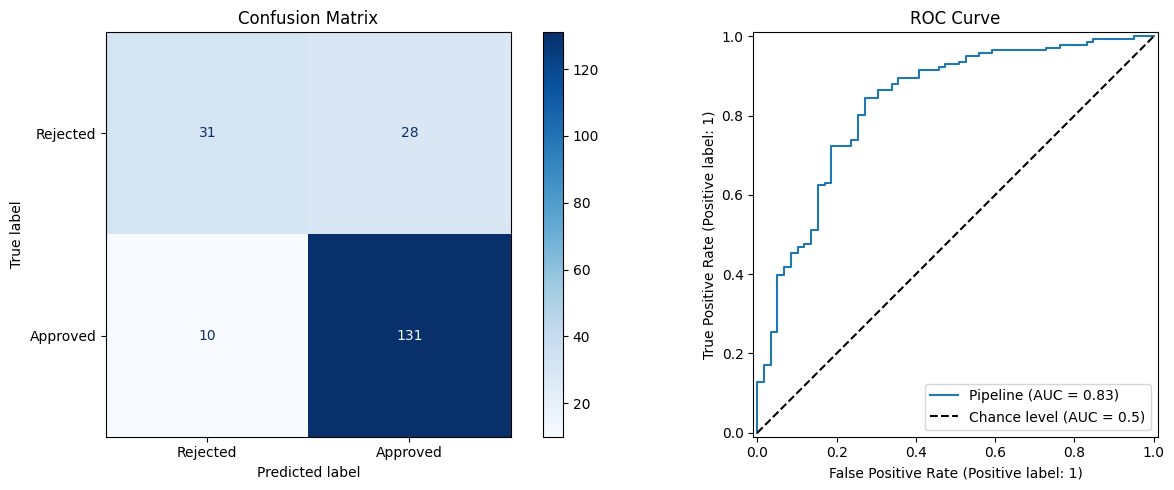

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate

# --- 1. Plotting the Graphs ---
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Rejected', 'Approved'])
cm_display.plot(ax=ax[0], cmap='Blues', values_format='d')
ax[0].set_title('Confusion Matrix')

# ROC Curve
RocCurveDisplay.from_estimator(model_pipeline, X_test, y_test, ax=ax[1])
ax[1].plot([0, 1], [0, 1], 'k--', label='Chance level (AUC = 0.5)')
ax[1].set_title('ROC Curve')
ax[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# --- 2. Bias and Variance Analysis via Cross-Validation ---
# We perform 5-fold cross-validation and return train scores to inspect bias vs variance
cv_results = cross_validate(
    model_pipeline, X, y, cv=5,
    return_train_score=True, scoring='accuracy'
)

train_scores = cv_results['train_score']
test_scores = cv_results['test_score']

mean_train_err = 1 - train_scores.mean()
mean_test_err = 1 - test_scores.mean()
variance_test_score = test_scores.var()

print(f"Average Training Error (Bias indicator): {mean_train_err:.4f}")
print(f"Average Test/Validation Error: {mean_test_err:.4f}")
print(f"Difference between Train and Test Error: {abs(mean_train_err - mean_test_err):.4f}")
print(f"Variance of Test Scores across Folds: {variance_test_score:.6f}\n")

# Interpretation
if mean_train_err > 0.20:
    bias_status = "High Bias (Underfitting) - The model is too simple for the underlying patterns."
else:
    bias_status = "Low Bias - The model fits the training data well."

if abs(mean_train_err - mean_test_err) > 0.05 or variance_test_score > 0.005:
    variance_status = "High Variance (Overfitting) - The model changes significantly with different training sets."
else:
    variance_status = "Low Variance - The model is highly stable and generalizes well to unseen folds."

print(f"Bias Assessment: {bias_status}")
print(f"Variance Assessment: {variance_status}")

Average Training Error (Bias indicator): 0.1755
Average Test/Validation Error: 0.1770
Difference between Train and Test Error: 0.0015
Variance of Test Scores across Folds: 0.000316

Bias Assessment: Low Bias - The model fits the training data well.
Variance Assessment: Low Variance - The model is highly stable and generalizes well to unseen folds.
